

### Project Objective:
The objective of this exploratory project is to build, evaluate, and interpret classical machine learning models to accurately predict the phase of High-Entropy Alloys (HEAs) from their chemical compositions, thermodynamic properties, and processing parameters.

### Target Classes (`Phases`):
1. **`BCC_SS`**: Single-phase Body-Centered Cubic Solid Solution
2. **`FCC_SS`**: Single-phase Face-Centered Cubic Solid Solution
3. **`FCC_PLUS_BCC`**: Dual Solid Solution (FCC + BCC duplex)
4. **`Im`**: Intermetallic phase / Multi-phase containing intermetallic compounds


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
import xgboost as xgb

import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
sns.set_theme(style='whitegrid')

In [3]:
df = pd.read_csv('Data Set HEAs_1400.csv', encoding='cp1252')
print(f"Initial Dataset Shape: {df.shape}")
df.head(3)

Initial Dataset Shape: (1361, 53)


,Alloy ID,Alloy,Al,Co,Cr,Fe,Ni,Cu,Mn,Ti,...,Quenching,HPR,Microstructure_,Multiphase,IM_Structure,Microstructure,Phases,References,Unnamed: 51,Unnamed: 52
0,Alloy 0000,Al0.5NbTaTiV,0.111111,0.0,0.0,0.0,0.0,0.0,0.0,0.222222,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.1016/j.proeng.2012.03.043,NaN,NaN
1,Alloy 0001,Al0.75MoNbTiV,0.157895,0.0,0.0,0.0,0.0,0.0,0.0,0.210526,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.3390/e16020870,NaN,NaN
2,Alloy 0002,Al0.25MoNbTiV,0.058824,0.0,0.0,0.0,0.0,0.0,0.0,0.235294,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.3390/e16020870,NaN,NaN


In [4]:
print("Dataset Info:")
df.info()

print("\nMissing Values Count (Top 15 Columns with Nulls):")
null_counts = df.isnull().sum()
print(null_counts[null_counts > 0].sort_values(ascending=False).head(15))

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1361 entries, 0 to 1360
Data columns (total 53 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alloy ID              1360 non-null   object 
 1   Alloy                 1360 non-null   object 
 2   Al                    1360 non-null   float64
 3   Co                    1360 non-null   float64
 4   Cr                    1360 non-null   float64
 5   Fe                    1360 non-null   float64
 6   Ni                    1360 non-null   float64
 7   Cu                    1360 non-null   float64
 8   Mn                    1360 non-null   float64
 9   Ti                    1360 non-null   float64
 10  V                     1360 non-null   float64
 11  Nb                    1360 non-null   float64
 12  Mo                    1360 non-null   float64
 13  Zr                    1360 non-null   float64
 14  Hf                    1360 non-null   float64
 15  Ta     

Target Class Distribution:


,Count,Percentage (%)
Phases,,
Im,463,34.04
BCC_SS,441,32.43
FCC_SS,354,26.03
FCC_PLUS_BCC,102,7.50


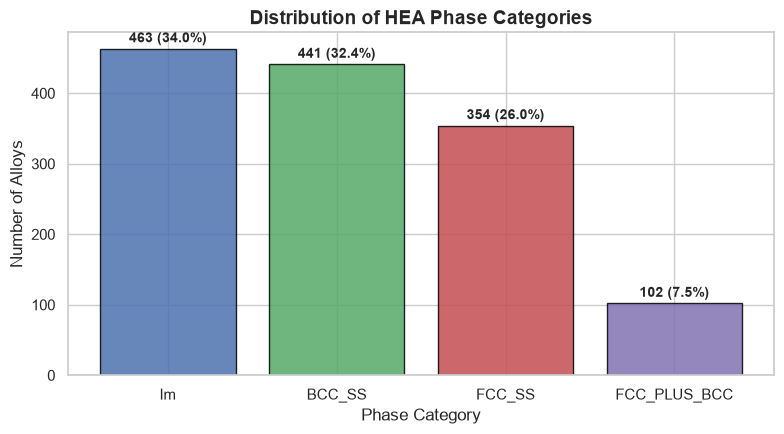

In [5]:
# Drop trailing empty row if present
df_clean = df.dropna(subset=['Phases']).copy()

phase_counts = df_clean['Phases'].value_counts()
phase_pct = df_clean['Phases'].value_counts(normalize=True) * 100

summary_target = pd.DataFrame({'Count': phase_counts, 'Percentage (%)': phase_pct.round(2)})
print("Target Class Distribution:")
display(summary_target)

plt.figure(figsize=(8, 4.5))
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B3']
bars = plt.bar(phase_counts.index, phase_counts.values, color=colors, edgecolor='black', alpha=0.85)
plt.title('Distribution of HEA Phase Categories', fontsize=14, fontweight='bold')
plt.xlabel('Phase Category', fontsize=12)
plt.ylabel('Number of Alloys', fontsize=12)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 5, f"{int(yval)} ({yval/len(df_clean)*100:.1f}%)", 
             ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

In [6]:
thermo_cols = ['Num_of_Elem', 'Density_calc', 'dHmix', 'dSmix', 'dGmix', 'Tm', 'n.Para', 'Atom.Size.Diff', 'Elect.Diff', 'VEC']
print("Descriptive Statistics of Key Thermodynamic Properties:")
df_clean[thermo_cols].describe().round(3).T

Descriptive Statistics of Key Thermodynamic Properties:


,count,mean,std,min,25%,50%,75%,max
Num_of_Elem,1360.0,4.958,0.831,2.000,5.000,5.000,5.000,7.000
Density_calc,1355.0,7.869,1.518,2.660,7.069,7.872,8.294,13.640
dHmix,1360.0,-6.599,6.602,-39.450,-10.960,-4.890,-2.696,4.160
dSmix,1360.0,12.542,1.734,3.466,11.530,13.146,13.380,16.179
dGmix,1360.0,474.889,111.793,171.461,387.097,467.623,548.685,825.650
Tm,1360.0,1823.725,430.136,646.935,1489.329,1801.200,2111.996,3157.750
n.Para,1359.0,9.147,21.810,0.559,2.090,4.654,8.540,279.277
Atom.Size.Diff,1360.0,4.415,2.291,0.168,3.262,4.430,5.655,19.060
Elect.Diff,1360.0,0.159,0.225,0.015,0.110,0.122,0.148,3.920
VEC,1360.0,6.538,1.660,3.161,4.600,7.200,8.000,9.500


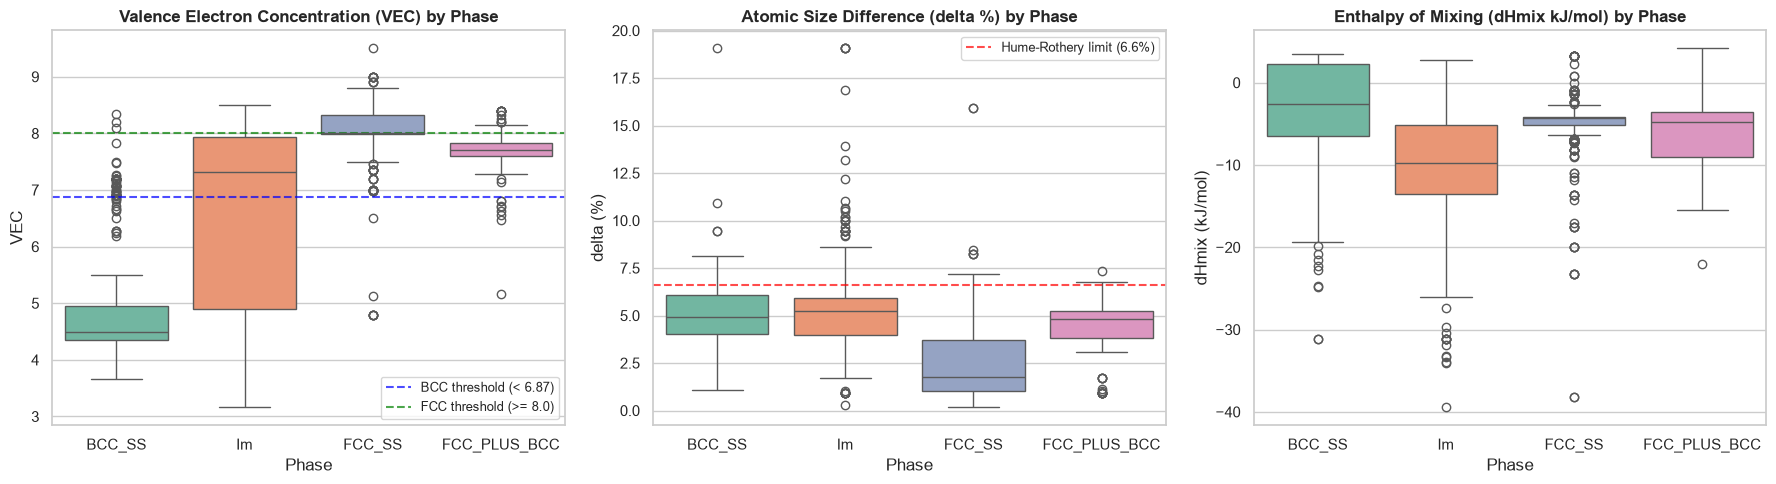

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Valence Electron Concentration (VEC)
sns.boxplot(data=df_clean, x='Phases', y='VEC', ax=axes[0], palette='Set2')
axes[0].set_title('Valence Electron Concentration (VEC) by Phase', fontweight='bold')
axes[0].set_ylabel('VEC')
axes[0].set_xlabel('Phase')
axes[0].axhline(6.87, color='blue', linestyle='--', alpha=0.7, label='BCC threshold (< 6.87)')
axes[0].axhline(8.0, color='green', linestyle='--', alpha=0.7, label='FCC threshold (>= 8.0)')
axes[0].legend(loc='lower right', fontsize=9)

# 2. Atomic Size Difference (delta %)
sns.boxplot(data=df_clean, x='Phases', y='Atom.Size.Diff', ax=axes[1], palette='Set2')
axes[1].set_title('Atomic Size Difference (delta %) by Phase', fontweight='bold')
axes[1].set_ylabel('delta (%)')
axes[1].set_xlabel('Phase')
axes[1].axhline(6.6, color='red', linestyle='--', alpha=0.7, label='Hume-Rothery limit (6.6%)')
axes[1].legend(loc='upper right', fontsize=9)

# 3. Enthalpy of Mixing (dHmix)
sns.boxplot(data=df_clean, x='Phases', y='dHmix', ax=axes[2], palette='Set2')
axes[2].set_title('Enthalpy of Mixing (dHmix kJ/mol) by Phase', fontweight='bold')
axes[2].set_ylabel('dHmix (kJ/mol)')
axes[2].set_xlabel('Phase')

plt.tight_layout()
plt.show()

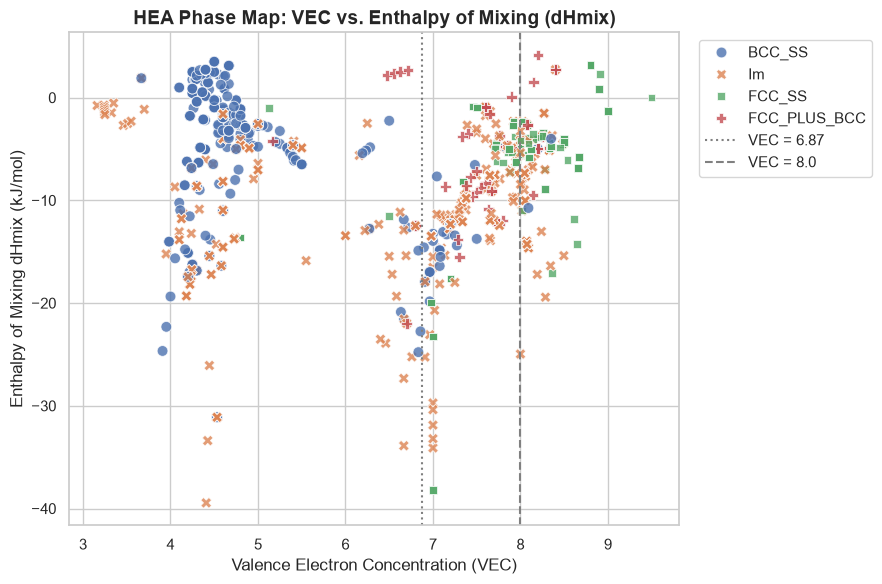

In [8]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_clean,
    x='VEC',
    y='dHmix',
    hue='Phases',
    style='Phases',
    s=60,
    alpha=0.8,
    palette='deep'
)
plt.title('HEA Phase Map: VEC vs. Enthalpy of Mixing (dHmix)', fontsize=14, fontweight='bold') #HEA means High entropy alloys
plt.xlabel('Valence Electron Concentration (VEC)', fontsize=12)
plt.ylabel('Enthalpy of Mixing dHmix (kJ/mol)', fontsize=12)
plt.axvline(6.87, color='gray', linestyle=':', label='VEC = 6.87')
plt.axvline(8.0, color='gray', linestyle='--', label='VEC = 8.0')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

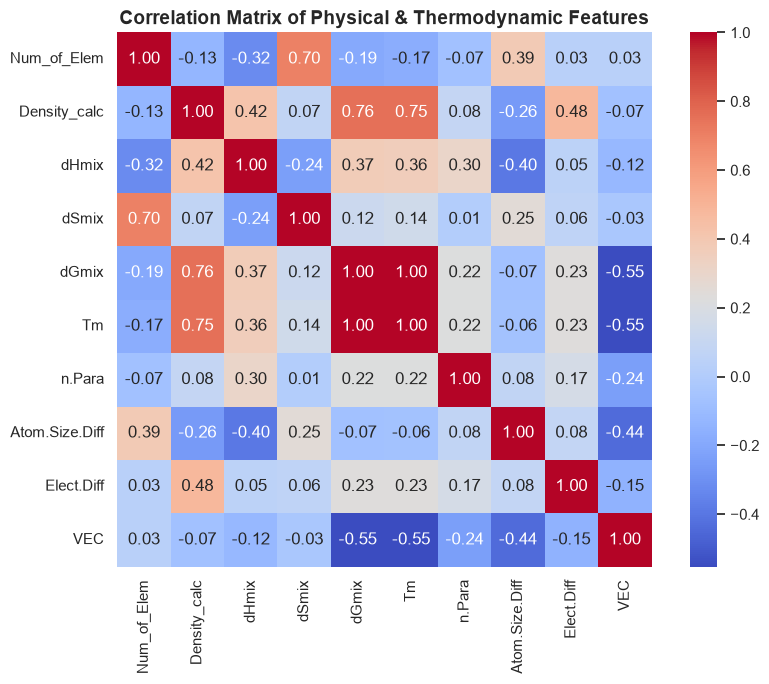

In [9]:
plt.figure(figsize=(9, 7))
corr = df_clean[thermo_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True)
plt.title('Correlation Matrix of Physical & Thermodynamic Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [10]:
elem_cols = ['Al', 'Co', 'Cr', 'Fe', 'Ni', 'Cu', 'Mn', 'Ti', 'V', 'Nb', 'Mo', 'Zr', 'Hf', 
             'Ta', 'W', 'C', 'Mg', 'Zn', 'Si', 'Re', 'N', 'Sc', 'Li', 'Sn', 'Be']

thermo_cols = ['Num_of_Elem', 'Density_calc', 'dHmix', 'dSmix', 'dGmix', 'Tm', 'n.Para', 
               'Atom.Size.Diff', 'Elect.Diff', 'VEC']

def parse_temperature(val):
    if pd.isnull(val):
        return 0.0
    val_str = str(val).replace('?', '').replace('°C', '').replace('K', '').strip()
    try:
        return float(val_str)
    except:
        return 0.0

df_clean['Homogenization_Temp_clean'] = df_clean['Homogenization_Temp'].fillna(0.0)
df_clean['Annealing_Temp_clean'] = df_clean['Annealing_Temp'].apply(parse_temperature)

route_dummies = pd.get_dummies(df_clean['Sythesis_Route'].fillna('AC'), prefix='Route', drop_first=True, dtype=float)

X = df_clean[elem_cols + thermo_cols].copy()
X['Density_calc'] = X['Density_calc'].fillna(X['Density_calc'].median())
X['n.Para'] = X['n.Para'].fillna(X['n.Para'].median())
X = pd.concat([X, route_dummies], axis=1)

X['Homogenization_Temp'] = df_clean['Homogenization_Temp_clean']
X['Annealing_Temp'] = df_clean['Annealing_Temp_clean']

le = LabelEncoder()
y = le.fit_transform(df_clean['Phases'])

label_mapping = dict(zip(le.classes_, range(len(le.classes_))))
print("Target Class Label Mapping:")
for phase_name, code in label_mapping.items():
    print(f"  {code}: {phase_name}")

print(f"\nFinal Feature Matrix Shape: {X.shape}")
print(f"Target Vector Shape: {y.shape}")

Target Class Label Mapping:
  0: BCC_SS
  1: FCC_PLUS_BCC
  2: FCC_SS
  3: Im

Final Feature Matrix Shape: (1360, 38)
Target Vector Shape: (1360,)


In [11]:
df.head()

,Alloy ID,Alloy,Al,Co,Cr,Fe,Ni,Cu,Mn,Ti,...,Quenching,HPR,Microstructure_,Multiphase,IM_Structure,Microstructure,Phases,References,Unnamed: 51,Unnamed: 52
0,Alloy 0000,Al0.5NbTaTiV,0.111111,0.0,0.0,0.0,0.0,0.0,0.0,0.222222,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.1016/j.proeng.2012.03.043,NaN,NaN
1,Alloy 0001,Al0.75MoNbTiV,0.157895,0.0,0.0,0.0,0.0,0.0,0.0,0.210526,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.3390/e16020870,NaN,NaN
2,Alloy 0002,Al0.25MoNbTiV,0.058824,0.0,0.0,0.0,0.0,0.0,0.0,0.235294,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.3390/e16020870,NaN,NaN
3,Alloy 0003,Al0.25NbTaTiV,0.058824,0.0,0.0,0.0,0.0,0.0,0.0,0.235294,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.1016/j.proeng.2012.03.043,NaN,NaN
4,Alloy 0004,Al0.2MoTaTiV,0.047619,0.0,0.0,0.0,0.0,0.0,0.0,0.238095,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.4028/www.scientific.net/MSF.898.638,NaN,NaN


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Samples: {X_train.shape[0]}")
print(f"Testing Samples:  {X_test.shape[0]}")
print(f"Number of Features: {X_train.shape[1]}")

Training Samples: 1088
Testing Samples:  272
Number of Features: 38


In [13]:
models = {
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=42), True),
    'k-Nearest Neighbors': (KNeighborsClassifier(n_neighbors=5), True),
    'Decision Tree': (DecisionTreeClassifier(random_state=42), False),
    'Random Forest': (RandomForestClassifier(n_estimators=200, random_state=42), False),
    'Extra Trees': (ExtraTreesClassifier(n_estimators=200, random_state=42), False),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=42), False),
    'XGBoost': (xgb.XGBClassifier(n_estimators=200, learning_rate=0.08, max_depth=5, eval_metric='mlogloss', random_state=42), False)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
benchmark_results = []
trained_models = {}

for name, (clf, use_scaled) in models.items():
    X_tr = X_train_scaled if use_scaled else X_train
    X_te = X_test_scaled if use_scaled else X_test
    
    cv_scores = cross_val_score(clf, X_tr, y_train, cv=cv, scoring='accuracy')
    clf.fit(X_tr, y_train)
    trained_models[name] = clf
    
    y_pred = clf.predict(X_te)
    test_acc = accuracy_score(y_test, y_pred)
    test_prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    test_rec = recall_score(y_test, y_pred, average='weighted')
    test_f1 = f1_score(y_test, y_pred, average='weighted')
    
    benchmark_results.append({
        'Model': name,
        'CV Accuracy (Mean)': round(cv_scores.mean() * 100, 2),
        'CV Accuracy (Std)': round(cv_scores.std() * 100, 2),
        'Test Accuracy (%)': round(test_acc * 100, 2),
        'Test Precision (%)': round(test_prec * 100, 2),
        'Test Recall (%)': round(test_rec * 100, 2),
        'Test F1-Score (%)': round(test_f1 * 100, 2)
    })

results_df = pd.DataFrame(benchmark_results).sort_values(by='Test Accuracy (%)', ascending=False).reset_index(drop=True)
print("Classical ML Model Benchmark Results:")
display(results_df)

Classical ML Model Benchmark Results:


,Model,CV Accuracy (Mean),CV Accuracy (Std),Test Accuracy (%),Test Precision (%),Test Recall (%),Test F1-Score (%)
0,Extra Trees,86.86,1.48,86.03,86.17,86.03,86.07
1,XGBoost,86.12,1.04,84.93,84.79,84.93,84.82
2,Random Forest,86.40,0.79,84.56,84.78,84.56,84.50
3,Decision Tree,84.93,1.12,82.35,82.64,82.35,82.42
4,Gradient Boosting,85.76,2.62,81.99,81.84,81.99,81.83
5,k-Nearest Neighbors,81.44,2.05,78.68,78.32,78.68,78.46
6,Logistic Regression,73.90,2.91,73.16,73.79,73.16,73.00


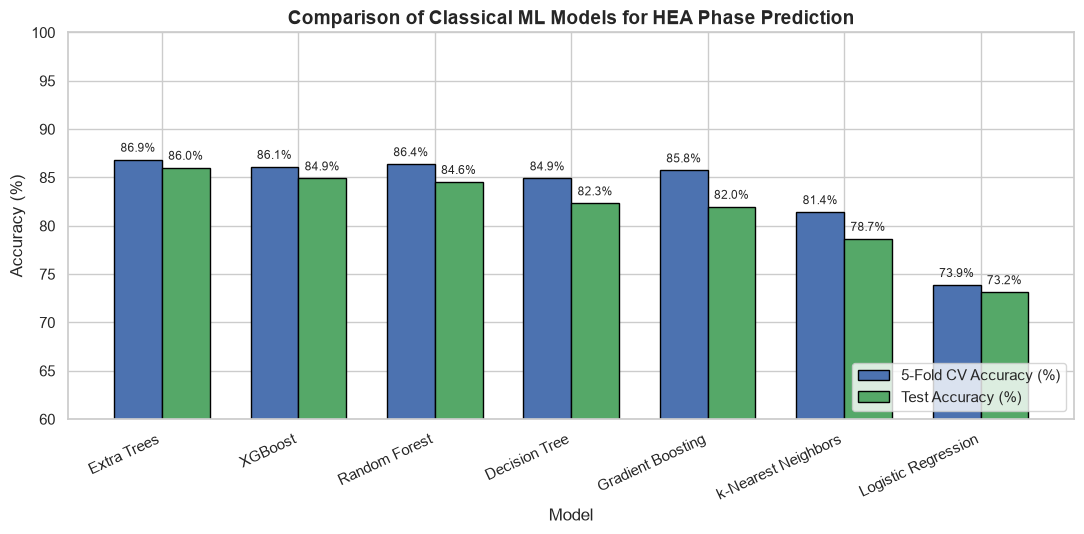

In [14]:
plt.figure(figsize=(11, 5.5))
x_idx = np.arange(len(results_df))
width = 0.35

plt.bar(x_idx - width/2, results_df['CV Accuracy (Mean)'], width, label='5-Fold CV Accuracy (%)', color='#4C72B0', edgecolor='black')
plt.bar(x_idx + width/2, results_df['Test Accuracy (%)'], width, label='Test Accuracy (%)', color='#55A868', edgecolor='black')

plt.title('Comparison of Classical ML Models for HEA Phase Prediction', fontsize=14, fontweight='bold')
plt.xlabel('Model', fontsize=12)
plt.ylabel('Accuracy (%)', fontsize=12)
plt.xticks(x_idx, results_df['Model'], rotation=25, ha='right')
plt.ylim(60, 100)
plt.legend(loc='lower right')

for i in range(len(results_df)):
    plt.text(i - width/2, results_df.loc[i, 'CV Accuracy (Mean)'] + 0.8, f"{results_df.loc[i, 'CV Accuracy (Mean)']:.1f}%", ha='center', fontsize=8.5)
    plt.text(i + width/2, results_df.loc[i, 'Test Accuracy (%)'] + 0.8, f"{results_df.loc[i, 'Test Accuracy (%)']:.1f}%", ha='center', fontsize=8.5)

plt.tight_layout()
plt.show()

=== Classification Report for Best Model: Extra Trees ===
              precision    recall  f1-score   support

      BCC_SS     0.8889    0.9091    0.8989        88
FCC_PLUS_BCC     0.7143    0.7500    0.7317        20
      FCC_SS     0.9254    0.8732    0.8986        71
          Im     0.8191    0.8280    0.8235        93

    accuracy                         0.8603       272
   macro avg     0.8369    0.8401    0.8382       272
weighted avg     0.8617    0.8603    0.8607       272



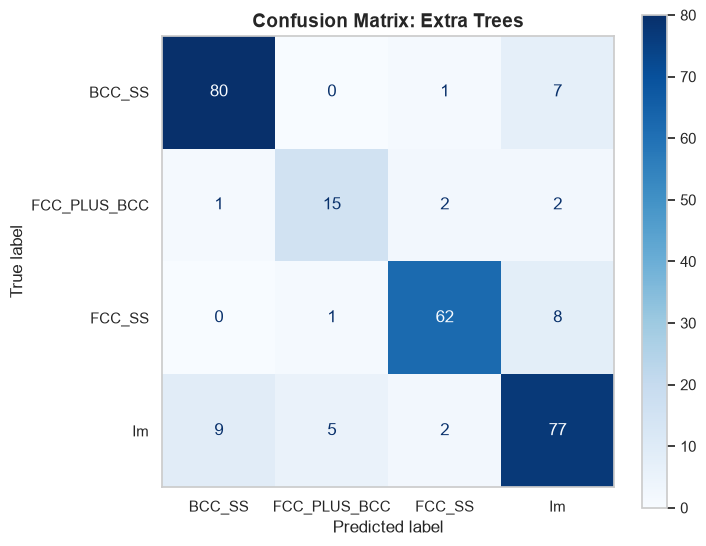

In [15]:
best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]
use_scaled = models[best_model_name][1]
X_eval = X_test_scaled if use_scaled else X_test

y_pred_best = best_model.predict(X_eval)

print(f"=== Classification Report for Best Model: {best_model_name} ===")
print(classification_report(y_test, y_pred_best, target_names=le.classes_, digits=4))

cm = confusion_matrix(y_test, y_pred_best)
fig, ax = plt.subplots(figsize=(7.5, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title(f'Confusion Matrix: {best_model_name}', fontsize=14, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

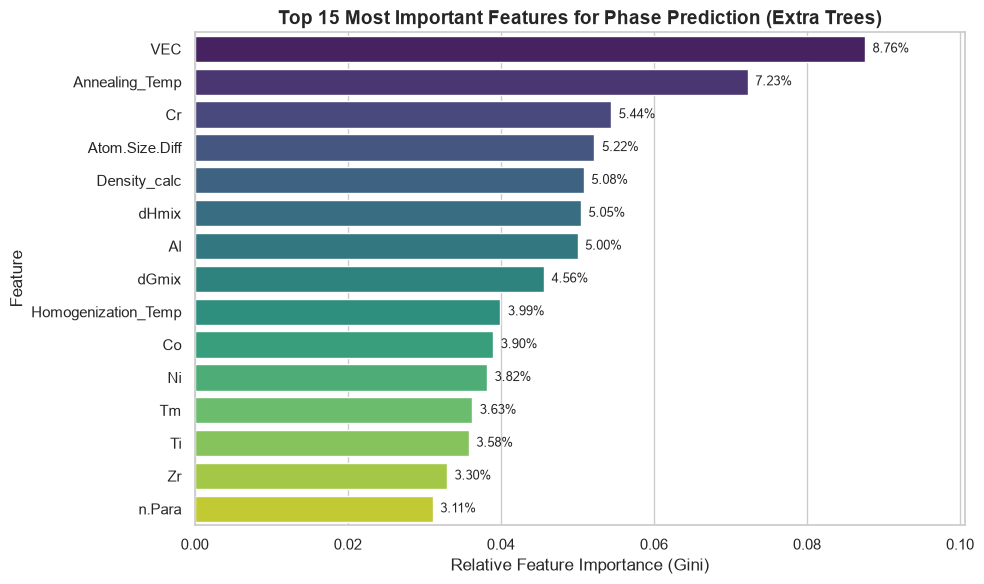

Top 10 Most Influential Features:
 1. VEC                 : 8.76%
 2. Annealing_Temp      : 7.23%
 3. Cr                  : 5.44%
 4. Atom.Size.Diff      : 5.22%
 5. Density_calc        : 5.08%
 6. dHmix               : 5.05%
 7. Al                  : 5.00%
 8. dGmix               : 4.56%
 9. Homogenization_Temp : 3.99%
10. Co                  : 3.90%


In [16]:
importances = best_model.feature_importances_
feat_importances = pd.Series(importances, index=X.columns).sort_values(ascending=False)

top_n = 15
plt.figure(figsize=(10, 6))
sns.barplot(x=feat_importances.head(top_n).values, y=feat_importances.head(top_n).index, palette='viridis')
plt.title(f'Top {top_n} Most Important Features for Phase Prediction ({best_model_name})', fontsize=14, fontweight='bold')
plt.xlabel('Relative Feature Importance (Gini)', fontsize=12)
plt.ylabel('Feature', fontsize=12)

for i, v in enumerate(feat_importances.head(top_n).values):
    plt.text(v + 0.001, i, f"{v*100:.2f}%", va='center', fontsize=9.5)

plt.xlim(0, max(feat_importances.head(top_n).values) * 1.15)
plt.tight_layout()
plt.show()

print("Top 10 Most Influential Features:")
for rank, (feat, score) in enumerate(feat_importances.head(10).items(), 1):
    print(f"{rank:2d}. {feat:20s}: {score*100:.2f}%")

### Metallurgical Insights from Feature Importance:
1. **Valence Electron Concentration (VEC)**: Confirms Guo's rule—VEC is the decisive separator between BCC ($VEC < 6.87$) and FCC ($VEC \ge 8.0$) solid solutions.
2. **Enthalpy of Mixing (dHmix) & Atomic Size Difference ($\delta$)**: Drive solid solution stability vs. intermetallic precipitation, consistent with Hume-Rothery and Yang-Zhang thermodynamic criteria.
3. **Elemental Fractions (e.g., Al, Ti, Ni, Fe)**:
   - **Aluminium (Al)**: Due to its large atomic radius and strong negative heat of mixing with transition metals, Al strongly drives intermetallic phase formation (e.g. B2, sigma) or BCC transitions.
   - **Titanium (Ti)**: Strong intermetallic former due to large atomic size difference.
   - **Ni and Co**: Classic FCC-stabilizing transition metals.
4. **Heat Treatment (Homogenization / Annealing)**: Confirms that processing history impacts whether metastable solid solutions transform into equilibrium intermetallics.

In [17]:
def predict_phase(alloy_input_df):
    probs = best_model.predict_proba(alloy_input_df)[0]
    pred_idx = np.argmax(probs)
    pred_phase = le.inverse_transform([pred_idx])[0]
    prob_dict = {phase: round(float(p) * 100, 2) for phase, p in zip(le.classes_, probs)}
    return pred_phase, prob_dict

sample_indices = [0, 10, 25]

print("=== Demonstration Predictions on Test Set Alloys ===\n")
for idx in sample_indices:
    test_sample = X_test.iloc[[idx]]
    actual_label = le.inverse_transform([y_test[idx]])[0]
    predicted_label, confidences = predict_phase(test_sample)
    
    print(f"Sample #{idx}:")
    print(f"  Actual Phase:    {actual_label}")
    print(f"  Predicted Phase: {predicted_label}")
    print(f"  Confidence:      {confidences[predicted_label]}%")
    print(f"  Class Probabilities: {confidences}")
    print("-" * 55)

=== Demonstration Predictions on Test Set Alloys ===

Sample #0:
  Actual Phase:    Im
  Predicted Phase: Im
  Confidence:      98.0%
  Class Probabilities: {'BCC_SS': 0.0, 'FCC_PLUS_BCC': 0.0, 'FCC_SS': 2.0, 'Im': 98.0}
-------------------------------------------------------
Sample #10:
  Actual Phase:    BCC_SS
  Predicted Phase: BCC_SS
  Confidence:      100.0%
  Class Probabilities: {'BCC_SS': 100.0, 'FCC_PLUS_BCC': 0.0, 'FCC_SS': 0.0, 'Im': 0.0}
-------------------------------------------------------
Sample #25:
  Actual Phase:    Im
  Predicted Phase: Im
  Confidence:      94.25%
  Class Probabilities: {'BCC_SS': 5.75, 'FCC_PLUS_BCC': 0.0, 'FCC_SS': 0.0, 'Im': 94.25}
-------------------------------------------------------


In [18]:
import joblib

artifacts = {
    'model': best_model,
    'label_encoder': le,
    'feature_names': list(X.columns),
    'elem_cols': elem_cols,
    'thermo_cols': thermo_cols,
    'feature_medians': X_train.median().to_dict(),
    'classes': list(le.classes_)
}

joblib.dump(artifacts, 'hea_phase_model.joblib')
print('Model and schemas successfully saved to hea_phase_model.joblib')
print(f'Total features saved: {len(artifacts["feature_names"])}')
print(f'Class labels: {artifacts["classes"]}')

Model and schemas successfully saved to hea_phase_model.joblib
Total features saved: 38
Class labels: ['BCC_SS', 'FCC_PLUS_BCC', 'FCC_SS', 'Im']
